# 04 · Bayesian optimization with BoTorch

**What you will learn.** How the loop of notebook 01 looks in [BoTorch](https://botorch.org), the PyTorch-based BO library OpenBO uses as its reference implementation; how its pieces map onto the ones you have already met; and what its defaults do differently from OpenBO's `GPScratch`.

**The four BoTorch pieces**

| step | notebook 01 (OpenBO scratch) | BoTorch |
|---|---|---|
| surrogate | `GPScratch` | `SingleTaskGP` (a GPyTorch model) |
| fit | `optimize_hyperparameters=True` | `fit_gpytorch_mll(ExactMarginalLogLikelihood(...))` |
| acquisition | `expected_improvement_maximization` | `LogExpectedImprovement` |
| find the next point | argmax over a grid or a Sobol pool, then L-BFGS-B | `optimize_acqf`: multistart gradient-based optimization through PyTorch autograd |

The notebook needs about 30 seconds. Everything is seeded.

In [1]:
import warnings
warnings.filterwarnings("ignore")            # BoTorch warns about input scaling, optimizer retries and a missing progress-bar widget
import numpy as np
import torch
import matplotlib.pyplot as plt

from botorch.models import SingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition import LogExpectedImprovement
from botorch.optim import optimize_acqf
from gpytorch.mlls import ExactMarginalLogLikelihood

from openbo.models.gp_scratch import GPScratch
from openbo.acquisition.ei import expected_improvement_maximization

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def f(x):                                    # the 1D toy objective of notebooks 01 and 03
    x = np.asarray(x, dtype=float)
    return 0.8 * np.exp(-((x - 0.25) / 0.08) ** 2) + np.exp(-((x - 0.75) / 0.1) ** 2) + 0.15 * np.sin(25 * x)

grid = np.linspace(0.0, 1.0, 1001)
def to_t(a):                                 # BoTorch works on double tensors of shape (n, d)
    return torch.tensor(np.asarray(a, dtype=float), dtype=torch.double)

## 1. The surrogate: `SingleTaskGP`

Fit a BoTorch GP to 12 observations of the toy function. We tell it to standardize the outcomes (`Standardize`), as `GPScratch` does by default. Then we ask for the posterior on a grid: BoTorch returns a *posterior object* whose `.mean` and `.variance` are tensors.

BoTorch default kernel: RBFKernel | fitted lengthscale: 0.084 | fitted noise variance: 2.6e-03
GPScratch (Matern-5/2)  : fitted lengthscale: 0.097


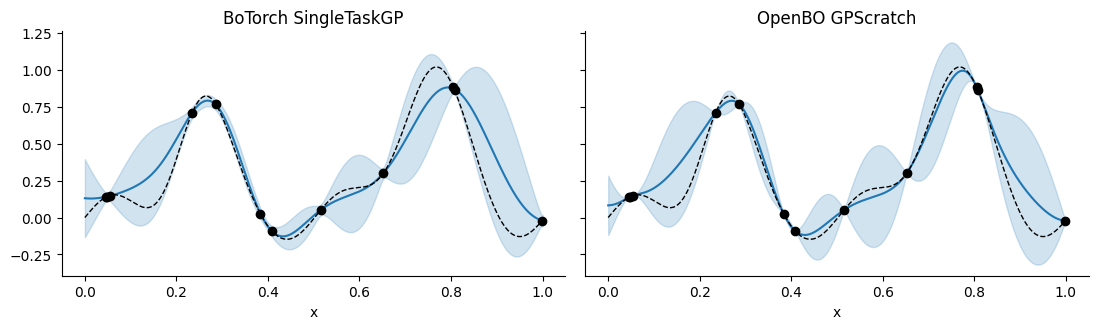

In [2]:
def fit_botorch_gp(x, y):
    model = SingleTaskGP(to_t(x[:, None]), to_t(y[:, None]), outcome_transform=Standardize(m=1))
    fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood, model))
    return model

def botorch_posterior(model, points):
    with torch.no_grad():
        post = model.posterior(to_t(points[:, None]))
    return post.mean.numpy().ravel(), post.variance.numpy().ravel()

x12 = np.sort(np.random.default_rng(5).uniform(0.0, 1.0, 12))
y12 = f(x12)
torch.manual_seed(0)
model = fit_botorch_gp(x12, y12)
mean_bt, var_bt = botorch_posterior(model, grid)

scratch = GPScratch(kernel_type="matern52", optimize_hyperparameters=True, optimizer_seed=0)
scratch.fit(x12[:, None], y12)
mean_sc, var_sc = scratch.posterior(grid[:, None])

print("BoTorch default kernel:", type(model.covar_module).__name__, "| fitted lengthscale:", round(model.covar_module.lengthscale.item(), 3),
      "| fitted noise variance:", f"{model.likelihood.noise.item():.1e}")
print("GPScratch (Matern-5/2)  : fitted lengthscale:", round(float(scratch.lengthscale[0]), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (name, mu, va) in zip(axes, (("BoTorch SingleTaskGP", mean_bt, var_bt), ("OpenBO GPScratch", mean_sc, var_sc))):
    sd = np.sqrt(va)
    ax.plot(grid, mu, color="C0"); ax.fill_between(grid, mu - 2 * sd, mu + 2 * sd, color="C0", alpha=0.2)
    ax.plot(grid, f(grid), "k--", lw=1); ax.scatter(x12, y12, c="k", zorder=5); ax.set_title(name); ax.set_xlabel("x")
plt.tight_layout(); plt.show()

With 12 points the two surrogates are close. Three differences are worth knowing:

- **Kernel.** BoTorch's default `SingleTaskGP` uses an RBF kernel (version 0.17 here), `GPScratch` defaults to Matérn-5/2. You can pass any GPyTorch kernel to BoTorch.
- **Priors.** BoTorch puts a prior on the lengthscale and on the noise and fits the *posterior mode* instead of the plain marginal likelihood. The prior keeps the fit away from silly values when data is scarce; `GPScratch` has no prior.
- **Noise.** BoTorch fits the observation noise (here about 3e-3); `GPScratch` keeps it fixed at `1e-6` unless asked (`optimize_noise=True`).

The prior matters most with very few points. Recall the 3-observation failure of notebook 02, where `GPScratch` chose a lengthscale of 0.002. Same three points, BoTorch:

lengthscale fitted from 3 points: BoTorch 0.083 | GPScratch 0.0025


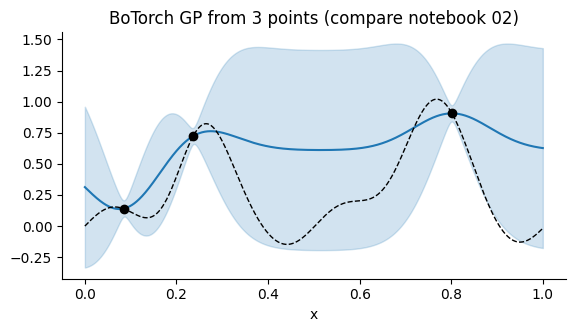

In [3]:
x3 = np.random.default_rng(3).uniform(0.0, 1.0, 3)
y3 = f(x3)
torch.manual_seed(0)
model3 = fit_botorch_gp(x3, y3)
mean3, var3 = botorch_posterior(model3, grid)
scratch3 = GPScratch(kernel_type="matern52", optimize_hyperparameters=True, optimizer_seed=0)
scratch3.fit(x3[:, None], y3)
print("lengthscale fitted from 3 points: BoTorch", round(model3.covar_module.lengthscale.item(), 3), "| GPScratch", round(float(scratch3.lengthscale[0]), 4))

sd3 = np.sqrt(var3)
plt.figure(figsize=(6.5, 3.2))
plt.plot(grid, mean3, color="C0"); plt.fill_between(grid, mean3 - 2 * sd3, mean3 + 2 * sd3, color="C0", alpha=0.2)
plt.plot(grid, f(grid), "k--", lw=1); plt.scatter(x3, y3, c="k", zorder=5)
plt.title("BoTorch GP from 3 points (compare notebook 02)"); plt.xlabel("x"); plt.show()

BoTorch's fit stays sensible here (the band is wide away from the data, and the mean follows the points). That is one dataset, not a guarantee, but it is the usual reason BoTorch is more forgiving when the initial design is tiny.

## 2. The acquisition function: `LogExpectedImprovement`

BoTorch's `LogExpectedImprovement(model, best_f)` computes the **logarithm** of EI. Why the log? Far from the incumbent, EI is astronomically small; in floating point it underflows to exactly 0, and a gradient-based optimizer then sees a flat zero landscape and cannot move. The log keeps a usable signal. First check that it agrees with OpenBO's EI computed from the same posterior:

max relative difference between exp(logEI) and OpenBO's EI (where EI > 1e-9): 5.1e-06
same argmax: True
grid points where OpenBO's EI underflows to exactly 0: 73 of 1001; where logEI is -inf or nan: 0


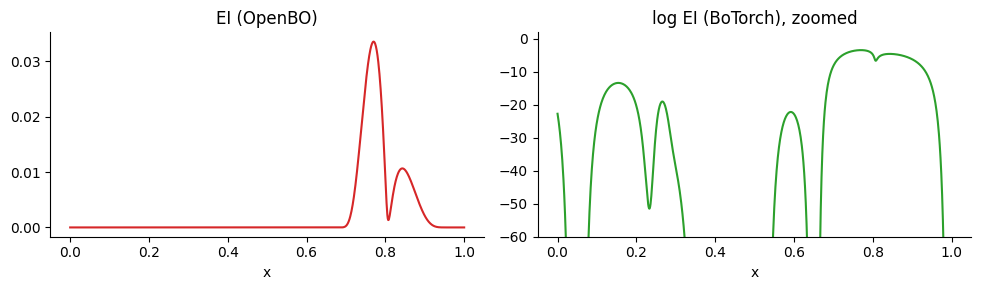

In [4]:
best = float(y12.max())
log_ei = LogExpectedImprovement(model=model, best_f=best)
with torch.no_grad():
    log_ei_vals = log_ei(to_t(grid[:, None, None])).numpy().ravel()          # input shape (n, q=1, d)
openbo_ei = expected_improvement_maximization(mean_bt, var_bt, best)           # OpenBO's EI on BoTorch's own posterior

ok = openbo_ei > 1e-9
print("max relative difference between exp(logEI) and OpenBO's EI (where EI > 1e-9):",
      f"{np.max(np.abs(np.exp(log_ei_vals[ok]) - openbo_ei[ok]) / openbo_ei[ok]):.1e}")
print("same argmax:", int(np.argmax(log_ei_vals)) == int(np.argmax(openbo_ei)))
print(f"grid points where OpenBO's EI underflows to exactly 0: {int((openbo_ei == 0).sum())} of {len(grid)}; "
      f"where logEI is -inf or nan: {int((~np.isfinite(log_ei_vals)).sum())}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
axes[0].plot(grid, openbo_ei, color="C3"); axes[0].set_title("EI (OpenBO)")
axes[1].plot(grid, log_ei_vals, color="C2"); axes[1].set_title("log EI (BoTorch), zoomed")
axes[1].set_ylim(-60, 2)          # at the observed points log EI plunges far below this (EI is 0 there); we zoom on the rest
for ax in axes: ax.set_xlabel("x")
plt.tight_layout(); plt.show()

On the left, plain EI is exactly zero over most of the interval (73 grid points underflow; the plot just shows a flat line). On the right, log EI keeps a smooth, informative shape there (zoomed in: it plunges to very large negative values right at the observed points, where there is nothing left to learn, and varies smoothly elsewhere). A gradient-based optimizer can follow that signal, which is what lets `optimize_acqf` work.

## 3. Finding the next point: `optimize_acqf`

Instead of scoring a grid, BoTorch **optimizes** the acquisition function: it draws `raw_samples` random points, keeps the best `num_restarts`, and refines each by gradient ascent (autograd gives the gradients for free). It returns the best point and its value, in any dimension and with constraints if you add them. We compare with the brute-force answer on our fine grid.

In [5]:
torch.manual_seed(0)
candidate, value = optimize_acqf(log_ei, bounds=torch.tensor([[0.0], [1.0]], dtype=torch.double), q=1, num_restarts=8, raw_samples=64)
print(f"optimize_acqf: x = {candidate.item():.4f}, log EI = {value.item():.3f}")
print(f"grid argmax  : x = {grid[np.argmax(log_ei_vals)]:.4f}, log EI = {log_ei_vals.max():.3f}")

optimize_acqf: x = 0.7701, log EI = -3.395
grid argmax  : x = 0.7700, log EI = -3.395


They agree. In 1D the grid is just as good, but in 6 dimensions a grid with 1000 points per axis is impossible, which is why continuous optimization of the acquisition function is the standard approach (OpenBO's scratch optimizer does the equivalent with a Sobol pool plus L-BFGS-B).

## 4. The whole loop

Put the three steps together (this is what OpenBO's `BoTorchSequentialOptimizer` does internally, plus bookkeeping), and run it on the toy function for 10 iterations starting from 3 points.

best value found: 1.0196 at x = 0.768  (true maximum 1.0196 at x = 0.768)


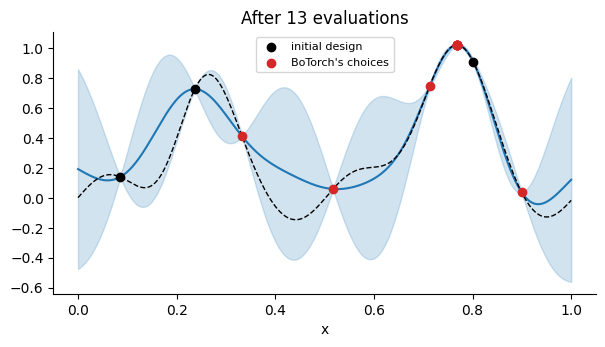

In [6]:
def botorch_bo_1d(f, x_init, n_iter, seed=0):
    torch.manual_seed(seed)
    x, y = np.array(x_init, dtype=float), f(np.array(x_init, dtype=float))
    for _ in range(n_iter):
        model = fit_botorch_gp(x, y)                                                       # 1. fit
        acq = LogExpectedImprovement(model=model, best_f=float(y.max()))                   # 2. score ...
        x_next, _ = optimize_acqf(acq, bounds=torch.tensor([[0.0], [1.0]], dtype=torch.double),
                                  q=1, num_restarts=8, raw_samples=64)                     #    ... and optimize
        x_next = float(x_next.item())
        x, y = np.append(x, x_next), np.append(y, f(x_next))                               # 3. evaluate
    return x, y

x_all, y_all = botorch_bo_1d(f, x3, n_iter=10)
final_model = fit_botorch_gp(x_all, y_all)
mu, va = botorch_posterior(final_model, grid)
print(f"best value found: {y_all.max():.4f} at x = {x_all[np.argmax(y_all)]:.3f}  (true maximum {f(grid).max():.4f} at x = {grid[np.argmax(f(grid))]:.3f})")

sd = np.sqrt(va)
plt.figure(figsize=(7, 3.4))
plt.plot(grid, mu, color="C0"); plt.fill_between(grid, mu - 2 * sd, mu + 2 * sd, color="C0", alpha=0.2)
plt.plot(grid, f(grid), "k--", lw=1)
plt.scatter(x_all[:3], y_all[:3], c="k", zorder=5, label="initial design")
plt.scatter(x_all[3:], y_all[3:], c="C3", zorder=5, label="BoTorch's choices")
plt.legend(fontsize=8); plt.xlabel("x"); plt.title("After 13 evaluations"); plt.show()

## 5. OpenBO's wrappers, side by side with the scratch optimizer, on Branin

OpenBO exposes the BoTorch loop as `run_bo_botorch` (and, for servers and your own loops, as an ask/tell object `BoTorchSequentialOptimizer` with `bootstrap`, `suggest` and `observe`). It follows OpenBO's conventions: maximization, inputs in the unit cube, `(n, d)` arrays in and `(n,)` out. Let us run it next to `run_bo_scratch` and random search on Branin, 5 seeds each, 30 evaluations.

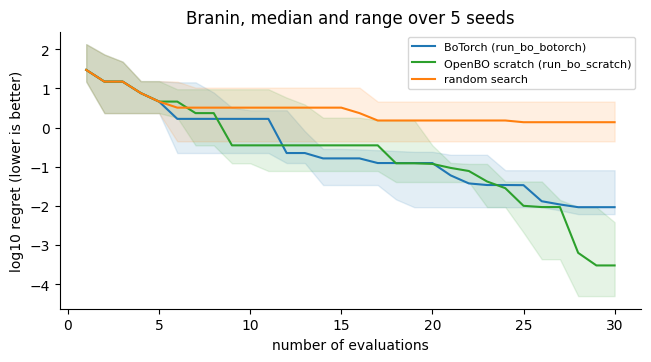

BoTorch (run_bo_botorch)           median final log10 regret  -2.03   total time for 5 runs:   5.6 s
OpenBO scratch (run_bo_scratch)    median final log10 regret  -3.52   total time for 5 runs:  11.1 s
random search                      median final log10 regret   0.14   total time for 5 runs:   0.0 s


In [7]:
import time
from openbo.optimizers.bo_botorch import run_bo_botorch
from openbo.optimizers.bo_scratch import run_bo_scratch
from openbo.test_functions.registry import get_function_spec

spec = get_function_spec("branin")
def log_regret(y):
    return np.log10(np.maximum(spec.optimum - np.maximum.accumulate(y), 1e-12))

n_evals, seeds = 30, range(5)
runs = {"BoTorch (run_bo_botorch)": [], "OpenBO scratch (run_bo_scratch)": [], "random search": []}
seconds = {k: 0.0 for k in runs}
for seed in seeds:
    t = time.perf_counter(); r = run_bo_botorch(spec.objective, spec.bounds, n_init=5, n_iter=n_evals - 5, seed=seed)
    seconds["BoTorch (run_bo_botorch)"] += time.perf_counter() - t; runs["BoTorch (run_bo_botorch)"].append(log_regret(r.y_obs))
    t = time.perf_counter(); r = run_bo_scratch(spec.objective, spec.bounds, n_init=5, n_iter=n_evals - 5, seed=seed)
    seconds["OpenBO scratch (run_bo_scratch)"] += time.perf_counter() - t; runs["OpenBO scratch (run_bo_scratch)"].append(log_regret(r.y_obs))
    runs["random search"].append(log_regret(spec.objective(np.random.default_rng(seed).random((n_evals, 2)))))

plt.figure(figsize=(7.5, 3.6))
for (name, curves), c in zip(runs.items(), ("C0", "C2", "C1")):
    arr = np.array(curves)
    plt.plot(np.arange(1, n_evals + 1), np.median(arr, 0), color=c, label=name); plt.fill_between(np.arange(1, n_evals + 1), arr.min(0), arr.max(0), color=c, alpha=0.12)
plt.xlabel("number of evaluations"); plt.ylabel("log10 regret (lower is better)"); plt.title("Branin, median and range over 5 seeds"); plt.legend(fontsize=8); plt.show()
for name, curves in runs.items():
    print(f"{name:34s} median final log10 regret {np.median([c[-1] for c in curves]):6.2f}   total time for {len(seeds)} runs: {seconds[name]:5.1f} s")

Both Bayesian optimizers beat random search by a wide margin, which is the point of the comparison. How the two compare *with each other* is not something five seeds on one function can settle (look at the spread of the shaded bands), and the timings depend on your machine. The differences you should expect come from the defaults listed above (kernel, priors, noise handling, and how the next point is searched), not from a better algorithm.

## When to use which

- **OpenBO's scratch implementation**: to *learn* (everything is a few hundred lines of NumPy you can read), to debug an idea, and where you do not want a PyTorch dependency in the loop.
- **BoTorch**: when you need what it has built in and the scratch code does not: batch suggestions (`q > 1`), constraints, multi-objective acquisition (OpenBO's `mobo_botorch` baseline), noisy or high-dimensional settings, GPU, or custom kernels and models.

## Takeaways

- The BoTorch loop is the same three steps: fit a model, build an acquisition function, optimize it.
- Its defaults differ from `GPScratch`: priors on the hyperparameters, a fitted noise term, a different default kernel.
- Gradient-based optimization of the acquisition function (with the log of EI for numerical stability) is how BO scales beyond a grid.

**Next:** `05_meta_bo_taf_conbo_naf` goes beyond a single task: what if you have optimized *related* functions before?